# Milestone 2 — Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`) nutzt dieses Notebook die
bereits vorbereiteten Daten aus `data/processed/cleaned_data.csv`. Die komplette
Datenbereinigung, Spektral-Interpolation, Feature-Engineering und Kodierung
erfolgt zentral in `pipeline/src/data_prep.py`. Dieses Notebook führt nur noch
Train/Test-Split, Cross-Validation, Modellvergleich, Hyperparameter-Tuning und
Fehleranalyse für RandomForest, HistGradientBoosting und MLP durch.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
PROCESSED_DATA_PATH = 'data/processed/cleaned_data.csv'
df = pd.read_csv(PROCESSED_DATA_PATH)

# Cleaning, interpolation, feature engineering, and encoding are performed
# by pipeline/src/data_prep.py. This notebook consumes that prepared dataset.
usable_spec_cols = sorted(
    [c for c in df.columns if c.startswith('X')],
    key=lambda c: int(c[1:]),
)
eng_cols = [
    c for c in df.columns
    if c not in usable_spec_cols + ['Crop', 'Stage', 'Month']
]

print(f'Loaded prepared data: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Usable spectral bands: {len(usable_spec_cols)}')
print(f'Engineered features: {len(eng_cols)}')
print(f'Missing values: {int(df.isna().sum().sum())}')


Loaded prepared data: 5591 rows, 166 columns
Usable spectral bands: 131
Engineered features: 32
Missing values: 0


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` — laut Feedback soll `Stage` ebenfalls berücksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf — das erhält gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [2]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage combinations, smallest: {combo_counts.idxmin()} with {combo_counts.min()} rows")
pd.crosstab(df['Crop'], df['Stage'])


23 Crop x Stage combinations, smallest: cotton|Harvest with 11 rows


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit bleibt 70/30 (Vergleichbarkeit mit M1), jetzt aber stratifiziert auf `Crop_Stage`. Zusätzlich prüfen wir kurz, ob andere Split-Verhältnisse (80/20, 90/10) das Ergebnis spürbar verändern.

In [3]:
feature_cols_plain = usable_spec_cols + ['Month']
feature_cols_cyclic = usable_spec_cols + ['Month_sin', 'Month_cos']
feature_cols_fe = [c for c in df.columns if c not in ['Crop', 'Stage', 'Crop_Stage']]

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

feature_sets = {
    name: {'train': df.loc[train_idx, cols], 'test': df.loc[test_idx, cols]}
    for name, cols in [('plain_month', feature_cols_plain), ('cyclic_month', feature_cols_cyclic), ('plain_month+fe', feature_cols_fe)]
}

y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

for name, fs in feature_sets.items():
    print(f"{name:15s} Train: {fs['train'].shape}  Test: {fs['test'].shape}")



plain_month     Train: (3913, 132)  Test: (1678, 132)
cyclic_month    Train: (3913, 133)  Test: (1678, 133)
plain_month+fe  Train: (3913, 164)  Test: (1678, 164)


**Sensitivität gegenüber Split-Verhältnis:** Schnelle Kontrolle mit RandomForest (Default-Hyperparameter, plain Month), ob 70/30 gegenüber anderen gängigen Verhältnissen stark abweicht.

In [4]:
def quick_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

ratio_rows = []
for test_size in [0.3, 0.2, 0.1]:
    tr_idx, te_idx = train_test_split(df.index, test_size=test_size, stratify=combo, random_state=RANDOM_STATE)
    crop_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_crop.loc[tr_idx])
    stage_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_stage.loc[tr_idx])
    ratio_rows.append({
        'test_size': test_size,
        'crop_balanced_accuracy': balanced_accuracy_score(y_crop.loc[te_idx], crop_fit.predict(df.loc[te_idx, feature_cols_plain])),
        'stage_balanced_accuracy': balanced_accuracy_score(y_stage.loc[te_idx], stage_fit.predict(df.loc[te_idx, feature_cols_plain])),
    })

ratio_results = pd.DataFrame(ratio_rows)
ratio_results

,test_size,crop_balanced_accuracy,stage_balanced_accuracy
0,0.3,0.792525,0.764742
1,0.2,0.784283,0.770761
2,0.1,0.830254,0.794821


## Cross-Validation & Modellvergleich

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits — dieselbe Fold-Einteilung wird für alle Modelle und Zielgrößen verwendet. Verglichen werden `RandomForestClassifier` (Baseline-Konfiguration), `HistGradientBoostingClassifier` (scikit-learn, kein Zusatzpaket) und ein `MLPClassifier`, auf drei Feature-Sets: Rohbänder mit plain bzw. zyklischem Month und Rohbänder + Feature Engineering (`plain_month+fe`). Der Vergleich Rohbänder vs. `+fe` ist die Ablation, ob das Feature Engineering etwas bringt.

Alle Modelle laufen hier mit **Default-Hyperparametern** — das ist eine Vorauswahl, kein fairer Endvergleich: das MLP reagiert deutlich stärker auf seine Hyperparameter als die Baummodelle. Der faire Vergleich folgt im Abschnitt *Hyperparameter-Tuning*. Das MLP läuft aus Laufzeitgründen nur auf dem `+fe`-Set (es profitiert als einziges Modell von One-Hot-AEZ und Skalierung, und auf Rohbändern gibt es bereits RF/HGB als Referenz).

**Overfitting-Check:** `return_train_score=True` liefert zusätzlich die Balanced Accuracy auf den Trainingsfolds; `gap` = Train − CV. Eine hohe Train-Accuracy allein ist bei Bäumen normal — entscheidend ist ein hoher, stabiler CV-Score.

In [5]:
def make_pipe(clf):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('clf', clf)])

model_factories = {
    'RandomForest': lambda: RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'MLP': lambda: MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=300, early_stopping=True,
                                 random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(feature_sets['plain_month']['train'], combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for feat_name, feat in feature_sets.items():
        if model_name == 'MLP' and feat_name != 'plain_month+fe':
            continue
        for target_name, y_target in targets.items():
            scores = cross_validate(make_pipe(factory()), feat['train'], y_target, cv=cv_folds,
                                    scoring=['balanced_accuracy', 'f1_macro'], return_train_score=True, n_jobs=-1)
            cv_rows.append({
                'model': model_name,
                'feature_set': feat_name,
                'target': target_name,
                'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
                'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
                'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
                'gap': scores['train_balanced_accuracy'].mean() - scores['test_balanced_accuracy'].mean(),
            })
            print(model_name, feat_name, target_name, f"cv_bacc={cv_rows[-1]['cv_balanced_accuracy_mean']:.3f}", flush=True)

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])

def cv_score(model, target, feature_set='plain_month+fe'):
    return cv_results.query("model == @model and feature_set == @feature_set and target == @target")['cv_balanced_accuracy_mean'].item()

cv_results.round(3)

RandomForest plain_month Crop cv_bacc=0.779
RandomForest plain_month Stage cv_bacc=0.752
RandomForest cyclic_month Crop cv_bacc=0.781
RandomForest cyclic_month Stage cv_bacc=0.782
RandomForest plain_month+fe Crop cv_bacc=0.849
RandomForest plain_month+fe Stage cv_bacc=0.822
HistGradientBoosting plain_month Crop cv_bacc=0.823
HistGradientBoosting plain_month Stage cv_bacc=0.816
HistGradientBoosting cyclic_month Crop cv_bacc=0.825
HistGradientBoosting cyclic_month Stage cv_bacc=0.817
HistGradientBoosting plain_month+fe Crop cv_bacc=0.903
HistGradientBoosting plain_month+fe Stage cv_bacc=0.890


ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\pavit\AppData\Roaming\Python\Python314\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pavit\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\pavit\AppData\Roaming\Python\Python314\site-packages\sklearn\pipeline.py", line 663, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Us

## Hyperparameter-Tuning (gleiches Budget für HGB und MLP)

Ab hier nur noch das `+fe`-Set (in der CV oben für jedes Modell das beste). Getunt werden die beiden stärksten Modelle, **HistGradientBoosting und MLP**, jeweils für Crop und Stage — und das MLP zusätzlich auf dem **gemeinsamen Label** `Crop|Stage` (23 Klassen).

`RandomizedSearchCV` zieht aus dem Suchraster `n_iter` **zufällige Kombinationen** und bewertet jede mit denselben 5 CV-Folds; die beste wird auf dem ganzen Trainingssplit neu gefittet. `n_iter = 30` heißt also: 30 Konfigurationen × 5 Folds = 150 Fits pro Modell und Zielgröße. Beide Modelle bekommen **dasselbe Budget (30)**, damit der Vergleich fair ist — vorher wurde nur das Modell getunt, das mit Default-Werten vorne lag, und zwar mit nur 8 Kombinationen.

Lernrate und `alpha` werden **log-uniform** gezogen (`loguniform`) statt aus einer festen Liste — so deckt die Suche mehrere Größenordnungen gleichmäßig ab.

**Early Stopping** ist in diesem Raster für beide Modelle fest eingeschaltet (`max_iter=1000` nur als Obergrenze): Es hält 10 % der Trainingsdaten als Validierung zurück und bricht ab, sobald sich der Score dort nicht mehr verbessert. Das macht die Suche deutlich schneller, kann aber zu früh stoppen — im vorherigen Notebook (`milestone2_model.ipynb`) war beim MLP `early_stopping=False` die beste Wahl.

**Gemeinsames Label:** Das gemeinsame MLP sagt `Crop|Stage` vorher; die Vorhersage wird am `|` zerlegt und Crop und Stage separat mit Balanced Accuracy bewertet. Ausgewählt wird nach dem Mittelwert beider Werte, damit der Score direkt mit den separaten Modellen vergleichbar ist.

Hinweis: `best_score_` ist das Maximum über 30 Kandidaten und daher leicht optimistisch — die ehrliche Schätzung liefert erst der Testsplit unten.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import make_scorer, balanced_accuracy_score
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# cv_folds kommt aus der CV-Zelle oben (stratifiziert auf Crop|Stage) und wird hier bewusst NICHT neu definiert:
# so nutzen Default-CV, Tuning, gemeinsames HGB und Classifier Chain exakt dieselben 5 Folds.

N_ITER = 30
X_fe_train, X_fe_test = feature_sets['plain_month+fe']['train'], feature_sets['plain_month+fe']['test']

param_grids = {
    'HistGradientBoosting': {
        'clf__early_stopping': [True],
        'clf__max_iter': [1000], 
        'clf__learning_rate': loguniform(0.01, 0.3),
        'clf__max_depth': [None, 10, 20],
        'clf__max_leaf_nodes': [15, 31, 63],
        'clf__min_samples_leaf': [10, 20, 40],
        'clf__l2_regularization': [0.0, 0.1, 1.0]
    },
    'MLP': {
        'clf__early_stopping': [True],
        'clf__max_iter': [1000],
        'clf__hidden_layer_sizes': [(128,), (256,), (512,), (128, 64), (256, 128), (512, 256), (256, 128, 64)],
        'clf__alpha': loguniform(1e-4, 1.0),
        'clf__learning_rate_init': loguniform(1e-4, 1e-2),
        'clf__batch_size': [64, 200]
    },
}

def split_joint(pred):
    """'corn|Late' -> (Crop-Array, Stage-Array)"""
    parts = pd.Series(np.asarray(pred)).str.split('|', expand=True)
    return parts[0].to_numpy(), parts[1].to_numpy()

def joint_crop_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[0], split_joint(y_pred)[0])

def joint_stage_bacc(y_true, y_pred):
    return balanced_accuracy_score(split_joint(y_true)[1], split_joint(y_pred)[1])

joint_scoring = {
    'mean': make_scorer(lambda yt, yp: (joint_crop_bacc(yt, yp) + joint_stage_bacc(yt, yp)) / 2),
    'crop': make_scorer(joint_crop_bacc), 
    'stage': make_scorer(joint_stage_bacc)
}

tuned = {}
tuning_rows = []

for model_name in ['HistGradientBoosting', 'MLP']:
    for target_name in ['Crop', 'Stage', 'Joint']:
        if target_name == 'Joint' and model_name != 'MLP':
            continue  
            
        y_fit = combo_train if target_name == 'Joint' else targets[target_name]
        
        # Use RandomizedSearchCV. 
        # The speed up comes from early_stopping + loguniform distributions
        search = RandomizedSearchCV(
            estimator=make_pipe(model_factories[model_name]()),
            param_distributions=param_grids[model_name],
            n_iter=N_ITER,
            cv=cv_folds,
            scoring=joint_scoring if target_name == 'Joint' else 'balanced_accuracy',
            refit='mean' if target_name == 'Joint' else True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        
        search.fit(X_fe_train, y_fit)
        
        if target_name == 'Joint':
            r, i = search.cv_results_, search.best_index_
            cv = {'Crop': r['mean_test_crop'][i], 'Stage': r['mean_test_stage'][i]}
        else:
            cv = {target_name: search.best_score_}
            
        tuned[(model_name, target_name)] = {
            'estimator': search.best_estimator_, 
            'params': search.best_params_, 
            'cv': cv
        }
        
        for t, s in cv.items():
            tuning_rows.append({
                'model': model_name, 
                'strategie': 'gemeinsam' if target_name == 'Joint' else 'separat',
                'target': t, 
                'cv_bacc_default': cv_score(model_name, t) if target_name != 'Joint' else np.nan,
                'cv_bacc_tuned': s,
                'key': (model_name, target_name),  # Schlüssel in `tuned`
            })
            
        print(model_name, target_name, search.best_params_, {k: round(v, 3) for k, v in cv.items()}, flush=True)

HistGradientBoosting Crop {'clf__early_stopping': True, 'clf__l2_regularization': 0.1, 'clf__learning_rate': np.float64(0.17945214475454108), 'clf__max_depth': None, 'clf__max_iter': 1000, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 40} {'Crop': np.float64(0.903)}
HistGradientBoosting Stage {'clf__early_stopping': True, 'clf__l2_regularization': 1.0, 'clf__learning_rate': np.float64(0.07812639007238957), 'clf__max_depth': 20, 'clf__max_iter': 1000, 'clf__max_leaf_nodes': 63, 'clf__min_samples_leaf': 10} {'Stage': np.float64(0.875)}
MLP Crop {'clf__alpha': np.float64(0.0001707396743152812), 'clf__batch_size': 200, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (256, 128), 'clf__learning_rate_init': np.float64(0.0015930522616241021), 'clf__max_iter': 1000} {'Crop': np.float64(0.925)}
MLP Stage {'clf__alpha': np.float64(0.006672367170464205), 'clf__batch_size': 64, 'clf__early_stopping': True, 'clf__hidden_layer_sizes': (512, 256), 'clf__learning_rate_init': np.float64(0.

### Strategievergleich: separate Modelle vs. gemeinsames Label

Alle Zeilen getunt mit demselben Budget, CV-Score pro Zielgröße (bei den gemeinsamen Modellen nach dem Zerlegen der Vorhersage). Als Referenz zusätzlich ein **gemeinsames HGB** mit Default-Parametern — nicht getunt, weil es auf 23 Klassen ~4× langsamer ist und, wie die Fold-Werte zeigen, instabil trainiert.

In [ ]:
joint_hgb = cross_validate(make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)), X_fe_train, combo_train,
                           cv=cv_folds, scoring={'crop': joint_scoring['crop'], 'stage': joint_scoring['stage']}, n_jobs=-1)
print('Gemeinsames HGB, Crop pro Fold: ', joint_hgb['test_crop'].round(3))
print('Gemeinsames HGB, Stage pro Fold:', joint_hgb['test_stage'].round(3))

# eigene Liste statt tuning_rows.append(...): sonst entstehen beim erneuten Ausführen der Zelle doppelte Zeilen
ref_rows = [
    {'model': 'HistGradientBoosting', 'strategie': 'gemeinsam (Default, Referenz)', 'target': t,
     'cv_bacc_default': joint_hgb[f'test_{t.lower()}'].mean(), 'cv_bacc_tuned': np.nan, 'key': None}
    for t in ['Crop', 'Stage']
]
tuning_results = pd.DataFrame(tuning_rows + ref_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.drop(columns='key').round(3)

Gemeinsames HGB, Crop pro Fold:  [0.356 0.36  0.315 0.222 0.888]
Gemeinsames HGB, Stage pro Fold: [0.363 0.361 0.362 0.244 0.862]


,model,strategie,target,cv_bacc_default,cv_bacc_tuned
2,MLP,separat,Crop,0.928,0.925
4,MLP,gemeinsam,Crop,NaN,0.923
0,HistGradientBoosting,separat,Crop,0.906,0.903
6,HistGradientBoosting,"gemeinsam (Default, Referenz)",Crop,0.428,NaN
8,HistGradientBoosting,"gemeinsam (Default, Referenz)",Crop,0.428,NaN
3,MLP,separat,Stage,0.874,0.896
5,MLP,gemeinsam,Stage,NaN,0.895
1,HistGradientBoosting,separat,Stage,0.886,0.875
7,HistGradientBoosting,"gemeinsam (Default, Referenz)",Stage,0.438,NaN
9,HistGradientBoosting,"gemeinsam (Default, Referenz)",Stage,0.438,NaN


### Classifier Chain: Vorhersage des einen Ziels als Input für das andere

Dritte Strategie neben *separat* und *gemeinsames Label*: Zuerst sagt ein Modell **Crop** vorher, dann bekommt das **Stage**-Modell zusätzlich zu den Spektral-Features die vorhergesagten **Crop-Wahrscheinlichkeiten** (`P_corn`, `P_cotton`, …) als Features. Idee: Welches Stadium vorliegt, hängt stark von der Kultur ab (siehe Kreuztabelle oben — z. B. kommt `rice` nur in `Early_Mid`/`Late` vor, `winter_wheat` nie in `Critical`/`Early_Mid`). Zusätzlich wird die umgekehrte Richtung getestet (**Stage → Crop**).

**Leakage-Vermeidung (Out-of-fold-Vorhersagen):** Würde das Stage-Modell auf Crop-Vorhersagen trainiert, die das Crop-Modell auf *seinen eigenen* Trainingsdaten macht, wären diese fast perfekt (Training-Accuracy ≈ 1) — im Test macht das Crop-Modell aber Fehler. Das Stage-Modell würde der Crop-Spalte zu sehr vertrauen, und der CV-Score wäre zu optimistisch. Deshalb:
1. **Training:** Die Crop-Wahrscheinlichkeiten für die Trainingszeilen kommen aus einer *inneren* 5-fachen CV (`cross_val_predict`): jede Zeile wird von einem Crop-Modell vorhergesagt, das sie nicht gesehen hat. Darauf wird das Stage-Modell trainiert. Das Crop-Modell selbst wird danach auf allen Trainingszeilen gefittet.
2. **Vorhersage:** Das Crop-Modell sagt die Wahrscheinlichkeiten für die neuen Zeilen vorher, das Stage-Modell nutzt sie.

Das echte Crop-Label wird dabei nie als Feature verwendet. Die ganze Kette steckt in einem Estimator (`ChainedClassifier`); in der äußeren CV (dieselben `cv_folds`) läuft Schritt 1 deshalb in jedem Fold nur auf dessen Trainingsteil (verschachtelte CV) — der Validierungsteil fließt nirgends ein.

Als Bausteine dienen die **getunten separaten Modelle** (jeweils das per CV beste für Crop bzw. Stage). Deren Hyperparameter wurden ohne die zusätzlichen Wahrscheinlichkeits-Features gesucht; für das zweite Modell der Kette ist das eine Näherung. Es wird nur die Zielgröße am **Ende** der Kette bewertet — die erste entspricht dem separaten Modell.

In [ ]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone


class ChainedClassifier(BaseEstimator, ClassifierMixin):
    """Classifier Chain mit Out-of-fold-Wahrscheinlichkeiten.

    Wird auf dem gemeinsamen Label `Crop|Stage` gefittet -- nur damit beide Zielgrößen durch die
    sklearn-API (cross_validate, Scorer) gereicht werden -- und sagt `Crop|Stage` vorher.
    """

    def __init__(self, first_model, second_model, first_target='Crop', inner_cv=5, random_state=None):
        self.first_model = first_model
        self.second_model = second_model
        self.first_target = first_target
        self.inner_cv = inner_cv
        self.random_state = random_state

    def _with_proba(self, X, proba):
        P = pd.DataFrame(proba, index=X.index, columns=[f'P_{c}' for c in self.first_classes_])
        return pd.concat([X, P], axis=1)

    def fit(self, X, y):
        crop, stage = split_joint(y)
        y_first, y_second = (crop, stage) if self.first_target == 'Crop' else (stage, crop)
        inner = StratifiedKFold(n_splits=self.inner_cv, shuffle=True, random_state=self.random_state)
        # Out-of-fold: jede Trainingszeile bekommt Wahrscheinlichkeiten von einem Modell, das sie nicht gesehen hat
        oof_proba = cross_val_predict(clone(self.first_model), X, y_first, cv=inner, method='predict_proba')
        self.first_ = clone(self.first_model).fit(X, y_first)
        self.first_classes_ = self.first_.classes_  # gleiche (sortierte) Reihenfolge wie die Spalten von oof_proba
        self.second_ = clone(self.second_model).fit(self._with_proba(X, oof_proba), y_second)
        self.classes_ = np.unique(np.asarray(y))
        return self

    def predict(self, X):
        proba = self.first_.predict_proba(X)
        y_first = self.first_classes_[proba.argmax(axis=1)]
        y_second = self.second_.predict(self._with_proba(X, proba))
        crop, stage = (y_first, y_second) if self.first_target == 'Crop' else (y_second, y_first)
        return pd.Series(crop).astype(str).str.cat(pd.Series(stage).astype(str), sep='|').to_numpy()


def best_separate(target):
    """Modellname (HGB/MLP) des per CV besten getunten separaten Modells für `target`."""
    return max((info['cv'][target], model) for (model, key), info in tuned.items() if key == target)[1]


chain_rows = []
for first, second in [('Crop', 'Stage'), ('Stage', 'Crop')]:
    m_first, m_second = best_separate(first), best_separate(second)
    chain = ChainedClassifier(clone(tuned[(m_first, first)]['estimator']), clone(tuned[(m_second, second)]['estimator']),
                              first_target=first, random_state=RANDOM_STATE)
    scores = cross_validate(chain, X_fe_train, combo_train, cv=cv_folds,
                            scoring={'crop': joint_scoring['crop'], 'stage': joint_scoring['stage']}, n_jobs=-1)
    cv_second = scores[f'test_{second.lower()}']
    key = (f'{m_first} → {m_second}', f'Chain_{first}_{second}')
    tuned[key] = {'estimator': chain.fit(X_fe_train, combo_train), 'params': None, 'cv': {second: cv_second.mean()},
                  'strategie': f'Kette ({first} → {second})'}
    chain_rows.append({'model': key[0], 'strategie': f'Kette ({first} → {second})', 'target': second,
                       'cv_bacc_default': np.nan, 'cv_bacc_tuned': cv_second.mean(), 'key': key})
    print(f'Kette {first} → {second} ({key[0]}): {second} CV bacc pro Fold {cv_second.round(3)}, Mittel {cv_second.mean():.3f}',
          flush=True)

tuning_results = pd.DataFrame(tuning_rows + ref_rows + chain_rows).sort_values(['target', 'cv_bacc_tuned'], ascending=[True, False])
tuning_results.drop(columns='key').round(3)

**Modellauswahl:** Pro Zielgröße gewinnt der Kandidat (HGB separat, MLP separat, MLP gemeinsam, Classifier Chain) mit dem höchsten CV-Score in `cv_bacc_tuned`. Der Testsplit wird für die Auswahl **nicht** verwendet.

## Finaler Fit & Fehleranalyse

Die ausgewählten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie für CV/Tuning/Auswahl verwendet) ausgewertet — inkl. Confusion Matrix pro Klasse für die Fehleranalyse. Bei einem gemeinsamen Modell oder einer Kette wird die `Crop|Stage`-Vorhersage zerlegt.

Crop - Modell: MLP (separat) - Balanced Accuracy: 0.908, Macro F1: 0.895
              precision    recall  f1-score   support

        corn       0.95      0.91      0.93       630
      cotton       0.88      0.88      0.88       197
        rice       0.81      0.93      0.87        28
     soybean       0.89      0.92      0.91       501
winter_wheat       0.88      0.90      0.89       322

    accuracy                           0.91      1678
   macro avg       0.88      0.91      0.89      1678
weighted avg       0.91      0.91      0.91      1678



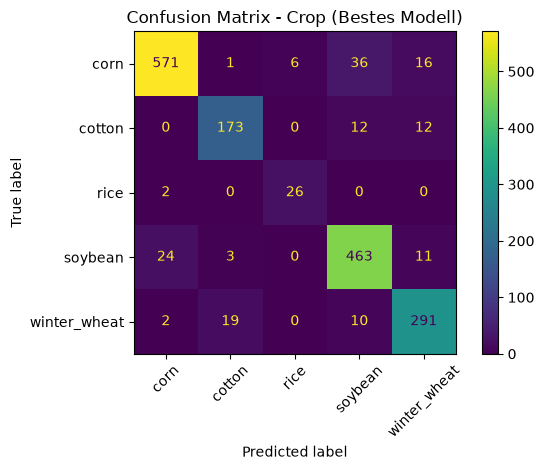

Stage - Modell: MLP (separat) - Balanced Accuracy: 0.892, Macro F1: 0.893
               precision    recall  f1-score   support

     Critical       0.91      0.94      0.93       462
    Early_Mid       0.87      0.88      0.87       295
Emerge_VEarly       0.87      0.91      0.89       312
      Harvest       0.89      0.89      0.89        54
         Late       0.96      0.93      0.95       258
Mature_Senesc       0.87      0.80      0.83       297

     accuracy                           0.90      1678
    macro avg       0.90      0.89      0.89      1678
 weighted avg       0.90      0.90      0.90      1678



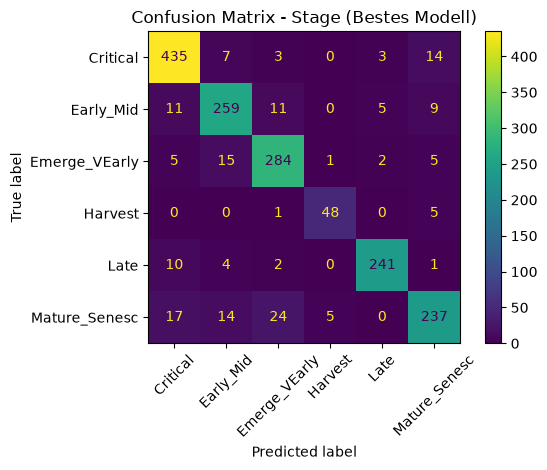

In [ ]:
# 1. Finde automatisch das beste Modell für 'Crop' und 'Stage' basierend auf dem höchsten CV-Score
best_per_target = {}

for target in ['Crop', 'Stage']:
    # Filtere die Ergebnisse nach dem aktuellen Target und ignoriere NaN-Werte (ungetunte Referenz)
    target_results = tuning_results[(tuning_results['target'] == target) & (tuning_results['cv_bacc_tuned'].notna())]

    # Finde die Zeile mit dem höchsten CV-Score
    best_row = target_results.loc[target_results['cv_bacc_tuned'].idxmax()]
    key = best_row['key']  # Schlüssel in `tuned`, z. B. ('MLP', 'Joint') oder ('MLP → MLP', 'Chain_Crop_Stage')

    best_per_target[target] = {
        'best_estimator': tuned[key]['estimator'],
        # gemeinsame Modelle und Ketten sagen 'Crop|Stage' vorher -> Vorhersage muss zerlegt werden
        'joint': key[1] != target,
        'label': f"{best_row['model']} ({best_row['strategie']})",
        'cv_best_score': best_row['cv_bacc_tuned'],
    }
    print(f"{target}: {best_per_target[target]['label']}  CV balanced_accuracy={best_row['cv_bacc_tuned']:.3f}")

# 2. Hilfsfunktion für die Vorhersage
def predict_target(estimator, joint, target_name, X):
    pred = estimator.predict(X)
    return split_joint(pred)[0 if target_name == 'Crop' else 1] if joint else pred

# 3. Evaluierung auf den Testdaten
for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    pred = predict_target(info['best_estimator'], info['joint'], target_name, X_fe_test)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['label']} - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (Bestes Modell)')
    plt.tight_layout()
    plt.show()

**Alle getunten Kandidaten auf dem Test-Split** — nur zur Einordnung (die Auswahl oben erfolgte allein per CV).

In [ ]:
test_rows = []
for (model_name, strat), info in tuned.items():
    for target_name, y_true in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
        if target_name not in info['cv']:
            continue
        pred = predict_target(info['estimator'], strat != target_name, target_name, X_fe_test)
        strategie = info.get('strategie', 'gemeinsam' if strat == 'Joint' else 'separat')
        test_rows.append({'target': target_name, 'model': model_name, 'strategie': strategie,
                          'cv_bacc': info['cv'][target_name], 'test_bacc': balanced_accuracy_score(y_true, pred),
                          'test_f1_macro': f1_score(y_true, pred, average='macro')})
test_results = pd.DataFrame(test_rows).sort_values(['target', 'cv_bacc'], ascending=[True, False])
test_results.round(3)

,target,model,strategie,cv_bacc,test_bacc,test_f1_macro
2,Crop,MLP,separat,0.925,0.908,0.895
4,Crop,MLP,gemeinsam,0.923,0.924,0.917
0,Crop,HistGradientBoosting,separat,0.903,0.888,0.879
3,Stage,MLP,separat,0.896,0.892,0.893
5,Stage,MLP,gemeinsam,0.895,0.907,0.908
1,Stage,HistGradientBoosting,separat,0.875,0.874,0.878


## Zusammenfassung & Vergleich ggü. Baseline

In [ ]:
rows = []
for target_name, m1_bacc, m1_f1, m2_bacc, m2_f1 in [('Crop', 0.778, 0.810, 0.877, 0.882), ('Stage', 0.769, 0.788, 0.874, 0.877)]:
    info = best_per_target[target_name]
    rows += [
        {'Zielgroesse': target_name, 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': m1_bacc, 'Macro F1': m1_f1},
        {'Zielgroesse': target_name, 'Modell': 'M2 ohne FE (HistGradientBoosting, Rohbaender)', 'Balanced Accuracy': m2_bacc, 'Macro F1': m2_f1},
        {'Zielgroesse': target_name, 'Modell': f"M2 final: {info['label']}",
         'Balanced Accuracy': info['test_bacc'], 'Macro F1': info['test_f1']},
    ]
summary = pd.DataFrame(rows)
summary.round(3)

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778,0.810
1,Crop,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.877,0.882
2,Crop,M2 final: MLP (separat),0.908,0.895
3,Stage,M1 Baseline (RandomForest),0.769,0.788
4,Stage,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.874,0.877
5,Stage,M2 final: MLP (separat),0.892,0.893


**Beobachtungen**

> **TODO nach dem Ausführen:** Die Zahlen unten mit den neuen Outputs abgleichen bzw. eintragen (`…`). Die Datenbasis (`cleaned_data.csv` aus der Pipeline, 32 statt 29 Zusatz-Features, kein roher `AEZ`-Wert mehr in den Rohband-Sets) und das Suchraster (Early Stopping fest an, log-uniforme Verteilungen) haben sich gegenüber `milestone2_model.ipynb` geändert — dessen Werte sind daher nicht direkt übertragbar.

- **Modellvergleich nach Tuning:** MLP Crop … vs. HGB …, Stage … vs. … (CV). Testsplit: …
- **Tuning-Effekt:** `cv_bacc_tuned` vs. `cv_bacc_default` pro Modell: … Liegt der getunte Wert *unter* dem Default, enthält das Suchraster die Default-Konfiguration nicht (z. B. Early Stopping fest an) — dann ist das Raster schlechter als die Standardwerte.
- **Strategievergleich (separat vs. gemeinsames Label vs. Kette):** Stage: separat …, gemeinsam …, Kette Crop → Stage …; Crop: separat …, gemeinsam …, Kette Stage → Crop … (CV). Unterschiede unter ~0.01 liegen im Bereich der Fold-Streuung bzw. der Seed-Schwankung des MLP.
- **Classifier Chain:** Die Kette nutzt ausschließlich vorhergesagte Wahrscheinlichkeiten (out-of-fold im Training), nie das echte Label des ersten Ziels — kein Leakage. Bringt sie gegenüber separat nichts, hat das zweite Modell die Information über das erste Ziel offenbar schon aus den Spektral-Features gelernt.
- **Gemeinsames HGB ist instabil:** In mehreren Folds bricht es auf ~0.2–0.4 ein, in anderen erreicht es ~0.9 — vermutlich numerische Probleme bei 23 Klassen, von denen manche sehr klein sind (`cotton|Harvest`: 11 Zeilen). Deshalb wird es nicht weiter verfolgt.
- **Feature Engineering (Ablation, CV, Default-Parameter):** HGB Crop … → …, Stage … → …; RF Crop … → …, Stage … → …. Achtung: Die Rohband-Sets enthalten keinen `AEZ` mehr, das `+fe`-Set aber die AEZ-One-Hot-Spalten — der Unterschied misst also FE **und** AEZ zusammen.
- **Overfitting-Check (gap = Train − CV, Default-Parameter):** HGB …, RF …, MLP …
- **Zyklisches Month-Encoding:** plain vs. zyklisch bei HGB …
- **Split-Verhältnis:** 70/30, 80/20, 90/10: …
- **Finale Testset-Ergebnisse (Auswahl per CV, Testsplit nie für CV/Tuning/Auswahl verwendet):** Crop … (Modell: …), Stage … (Modell: …).
- **Fehleranalyse:** schwächste/stärkste Klassen Crop: …; Stage: …
- **Einschränkungen:** Ein einziger Random Seed (MLP-Ergebnisse schwanken je nach Seed um ~0.01–0.02); `best_score_` ist als Maximum über 30 Kandidaten leicht optimistisch. Die Werte „M2 ohne FE“ in der Zusammenfassung sind fest eingetragen und stammen aus einem früheren Lauf.